# HapSleep — PoC con GLOBEM (Fitbit, estudiantes universitarios, 4 años)

**Qué es GLOBEM.** 705 persona-años de estudiantes universitarios (4 cohortes de primavera, 2018–2021, ~10 semanas cada una) con Fitbit y sensores del celular, más encuestas
(PHQ-4, BDI-II, CES-D, PSS-10, STAI, etc.). Es un dataset real, más grande que LifeSnaps (71 personas) y de la población objetivo de la tesis.

**Qué NO es (hay que decirlo desde el principio).**
- **No tiene PSQI ni ninguna encuesta de calidad de sueño.** Sus encuestas miden depresión, ansiedad, estrés y bienestar. Por eso **no sirve para entrenar ni validar "riesgo de mala calidad de sueño"**: esa etiqueta sigue pendiente (Capa A).
- **Su Fitbit solo entrega sueño y pasos.** No trae pulso en reposo, HRV, SpO2 ni respiración, que son 2 de los 5 grupos de variables del POC final (FC y HRV, y Respiración y oxígeno).
- Es una sola marca (Fitbit): no aporta evidencia multi-wearable.

**Entonces, ¿qué se prueba aquí?** Lo que el dataset sí permite, con n grande y sin etiqueta de sueño:
1. **Cobertura y calidad** de las variables que comparte con LifeSnaps.
2. **Estabilidad del rasgo por persona** (la tesis asume que el riesgo es un rasgo estable y no de una noche; se probó en LifeSnaps con 71 personas).
3. **La alerta del sedentarismo** (¿"minutos sedentarios" mide movimiento o solo tiempo sin reloj?).
4. **Validez convergente:** ¿las variables de sueño del reloj se relacionan con resultados de salud mental medidos con cuestionarios? (asociación, no predicción).
5. **Cuánto varía un modelo Random Forest con n = 37, 50, 100… personas**, usando un cuestionario real como etiqueta sustituta. Sirve para planear la validación de ~50 usuarios, **no** como desempeño de HapSleep.

In [1]:
import sys, json, re, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold
try: sys.stdout.reconfigure(encoding="utf-8")
except AttributeError: pass
warnings.filterwarnings("ignore"); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

ROOT = next(Path("../multiwearable/datasets/otros/globem_fitbit_multiyear").glob("globem-*"))
SEED, MIN_TST, MIN_NIGHTS = 42, 180, 10   # noche válida: >= 180 min dormidos; persona-año válida: >= 10 noches válidas

SLEEP = {"sumdurationasleepmain": "tst", "sumdurationawakemain": "awake", "sumdurationtofallasleepmain": "latency",
         "sumdurationinbedmain": "inbed", "avgefficiencymain": "eff", "firstbedtimemain": "bedtime"}
STEPS = {"sumsteps": "steps", "sumdurationsedentarybout": "sed", "sumdurationactivebout": "act"}
days = []
for y in range(1, 5):
    d = ROOT / f"INS-W_{y}"
    s = pd.read_csv(d / "FeatureData/sleep.csv", usecols=["pid", "date"] + [f"f_slp:fitbit_sleep_summary_rapids_{k}:allday" for k in SLEEP])
    s.columns = ["pid", "date"] + list(SLEEP.values())
    t = pd.read_csv(d / "FeatureData/steps.csv", usecols=["pid", "date"] + [f"f_steps:fitbit_steps_intraday_rapids_{k}:allday" for k in STEPS])
    t.columns = ["pid", "date"] + list(STEPS.values())
    x = s.merge(t, on=["pid", "date"], how="outer"); x["year"] = y; days.append(x)
D = pd.concat(days, ignore_index=True); D["date"] = pd.to_datetime(D["date"])
print(f"Filas persona-día: {len(D):,} | persona-años (pid distintos): {D.pid.nunique()}")
print("Los pid NO se repiten entre años (cada persona-año tiene su propio código).")

Filas persona-día: 69,602 | persona-años (pid distintos): 705
Los pid NO se repiten entre años (cada persona-año tiene su propio código).


## 1. Cobertura y calidad de las variables

Noche válida = al menos 180 minutos dormidos (hay 411 noches con 0 minutos, que son registros vacíos). Persona-año válida = al menos 10 noches válidas
(el mismo mínimo que usa el resto del proyecto).

In [2]:
D["valid_night"] = D.tst >= MIN_TST
g = D.groupby("pid")
cov = pd.DataFrame({"year": g.year.first(), "noches_validas": g.valid_night.sum(), "dias_con_pasos": g.steps.count()})
cov["persona_valida"] = cov.noches_validas >= MIN_NIGHTS
tab = cov.groupby("year").agg(personas=("persona_valida", "size"), validas=("persona_valida", "sum"),
                              noches_mediana=("noches_validas", "median"), dias_pasos_mediana=("dias_con_pasos", "median")).astype(int)
tab.loc["Total"] = [tab.personas.sum(), tab.validas.sum(), int(cov.noches_validas.median()), int(cov.dias_con_pasos.median())]
print(tab.to_string())
v = D[D.valid_night]
print(f"\nLatencia de sueño = 0 en el {(v.latency == 0).mean():.1%} de las noches válidas (igual que en LifeSnaps: Fitbit pone 0 por defecto) -> se descarta.")
tot = (D.sed + D.act).dropna()
print(f"Sedentarios + activos: exactamente 1440 min en el {(tot == 1440).mean():.1%} de los días con pasos (máximo {tot.max():.0f}): "
      "'sedentario' = 1440 - 'activo', o sea incluye el tiempo dormido y el tiempo sin reloj.")
print("Variables que HapSleep usa y GLOBEM NO tiene: pulso en reposo, HRV, SpO2, frecuencia respiratoria.")
tab

       personas  validas  noches_mediana  dias_pasos_mediana
year                                                        
1           155      130              57                  67
2           218      207              57                  63
3           137      130              64                  69
4           195      186              71                  74
Total       705      653              61                  65

Latencia de sueño = 0 en el 98.6% de las noches válidas (igual que en LifeSnaps: Fitbit pone 0 por defecto) -> se descarta.
Sedentarios + activos: exactamente 1440 min en el 100.0% de los días con pasos (máximo 1440): 'sedentario' = 1440 - 'activo', o sea incluye el tiempo dormido y el tiempo sin reloj.
Variables que HapSleep usa y GLOBEM NO tiene: pulso en reposo, HRV, SpO2, frecuencia respiratoria.


,personas,validas,noches_mediana,dias_pasos_mediana
year,,,,
1,155,130,57,67
2,218,207,57,63
3,137,130,64,69
4,195,186,71,74
Total,705,653,61,65


## 2. ¿El riesgo es un rasgo estable de la persona? (estabilidad)

La tesis agrega por persona (media y variación entre noches) porque la noche puntual es casi impredecible. Aquí se mide con ~700 persona-años:

- **Autocorrelación noche a noche** (¿una noche predice la siguiente?). En LifeSnaps era ~0.
- **Confiabilidad por mitades:** se calcula cada variable con las noches pares y con las impares de la misma persona, y se correlacionan entre personas (corregido con Spearman-Brown).
- **Estabilidad en el tiempo:** primera mitad del periodo contra la segunda.

Si la variable resume bien a la persona, ambas correlaciones serán altas aunque la autocorrelación de una noche sea baja.

In [3]:
def person_feats(df):
    df = df.sort_values("date")
    n = df[df.valid_night]
    return pd.Series({
        "tst_mean": n.tst.mean(), "tst_std": n.tst.std(), "awake_mean": n.awake.mean(), "awake_std": n.awake.std(),
        "eff_mean": n.eff.mean(), "eff_std": n.eff.std(), "bedtime_std": n.bedtime.std(),
        "steps_mean": df.steps.mean(), "steps_std": df.steps.std(), "sed_mean": df.sed.mean(), "sed_std": df.sed.std(),
        "n_nights": len(n)})
valid_pids = cov.index[cov.persona_valida]
DV = D[D.pid.isin(valid_pids)]
F = DV.groupby("pid").apply(person_feats)
F["year"] = cov.loc[F.index, "year"]
FEATS = [c for c in F.columns if c not in ("n_nights", "year")]
print(f"Persona-años válidas: {len(F)} | {len(FEATS)} variables por persona: {FEATS}")

# autocorrelación noche a noche (solo días consecutivos), promedio por Fisher z
def lag1(df, col):
    df = df.sort_values("date").set_index("date")[col]
    a = df[df.index.to_series().diff().shift(-1) == pd.Timedelta(days=1)]
    b = df.shift(-1).reindex(a.index)
    m = a.notna() & b.notna()
    if m.sum() < 15: return np.nan
    aa, bb = a[m] - df.mean(), b[m] - df.mean()
    return np.corrcoef(aa, bb)[0, 1]
Dn = DV[DV.valid_night]
ac = {c: np.nanmean(np.arctanh(np.clip(Dn.groupby("pid").apply(lambda g: lag1(g, c)).dropna(), -.99, .99))) for c in ["tst", "eff", "awake"]}
print("\nAutocorrelación noche a noche (media entre personas):", {k: round(float(np.tanh(v)), 2) for k, v in ac.items()})

rows = []
for f, (col, how) in {"tst_mean": ("tst", "mean"), "eff_mean": ("eff", "mean"), "awake_mean": ("awake", "mean"), "tst_std": ("tst", "std"),
                      "bedtime_std": ("bedtime", "std"), "steps_mean": ("steps", "mean"), "sed_mean": ("sed", "mean")}.items():
    odd, even, h1, h2 = {}, {}, {}, {}
    for pid, g in DV.groupby("pid"):
        s = (g[g.valid_night] if col in ("tst", "eff", "awake", "bedtime") else g.dropna(subset=[col])).sort_values("date")[col].dropna()
        if len(s) < 20: continue
        k = len(s) // 2
        fn = (lambda z: z.mean()) if how == "mean" else (lambda z: z.std())
        odd[pid], even[pid], h1[pid], h2[pid] = fn(s.iloc[::2]), fn(s.iloc[1::2]), fn(s.iloc[:k]), fn(s.iloc[k:])
    ids = list(odd)
    r = spearmanr([odd[i] for i in ids], [even[i] for i in ids]).correlation
    rt = spearmanr([h1[i] for i in ids], [h2[i] for i in ids]).correlation
    rows.append({"variable": f, "personas": len(ids), "pares vs impares (Spearman-Brown)": round(2 * r / (1 + r), 2), "1ª mitad vs 2ª mitad": round(rt, 2)})
stab = pd.DataFrame(rows).set_index("variable")
stab

Persona-años válidas: 653 | 11 variables por persona: ['tst_mean', 'tst_std', 'awake_mean', 'awake_std', 'eff_mean', 'eff_std', 'bedtime_std', 'steps_mean', 'steps_std', 'sed_mean', 'sed_std']



Autocorrelación noche a noche (media entre personas): {'tst': -0.04, 'eff': 0.07, 'awake': 0.07}


,personas,pares vs impares (Spearman-Brown),1ª mitad vs 2ª mitad
variable,,,
tst_mean,617,0.93,0.82
eff_mean,617,0.97,0.87
awake_mean,617,0.96,0.84
tst_std,617,0.84,0.69
bedtime_std,617,0.84,0.55
steps_mean,645,0.98,0.93
sed_mean,645,0.98,0.91


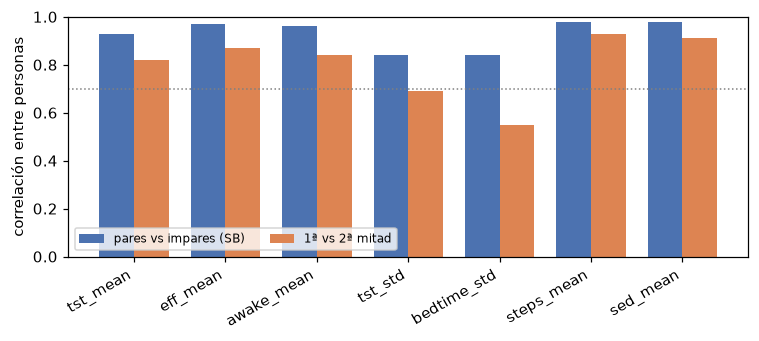

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(stab)); w = .38
ax.bar(x - w / 2, stab.iloc[:, 1], w, label="pares vs impares (SB)", color="#4C72B0")
ax.bar(x + w / 2, stab.iloc[:, 2], w, label="1ª vs 2ª mitad", color="#DD8452")
ax.set_xticks(x); ax.set_xticklabels(stab.index, rotation=30, ha="right"); ax.set_ylim(0, 1); ax.set_ylabel("correlación entre personas")
ax.axhline(0.7, color="grey", ls=":", lw=1); ax.legend(fontsize=8, ncol=2, loc="lower left"); plt.tight_layout(); plt.show()

## 3. La alerta del sedentarismo, otra vez

En LifeSnaps, el promedio de minutos sedentarios correlacionaba +0.88 con los minutos totales registrados (tiempo con reloj puesto), así que no se podía separar movimiento
de completitud de los datos. En GLOBEM los minutos sedentarios y los activos suman siempre 1440 (sección 1), así que "sedentario" es exactamente "1440 menos activo", y mide también el tiempo dormido
y el tiempo sin el reloj. Se comprueba qué tan redundante es con los pasos y cuánto tiempo sin reloj se ve.

In [5]:
pers = F[["steps_mean", "sed_mean"]].dropna()
print(f"Spearman entre personas, minutos sedentarios (media) vs pasos (media): {spearmanr(pers.steps_mean, pers.sed_mean).correlation:+.2f}  (n = {len(pers)})")
dd = DV.dropna(subset=["steps", "sed"])
print(f"Días con >= 1430 min 'sedentarios' (casi cero movimiento, lo típico de un reloj no puesto): {(dd.sed >= 1430).mean():.1%} de {len(dd):,} persona-días")
print(f"Días con menos de 500 pasos: {(dd.steps < 500).mean():.1%}")
print("Lectura: 'minutos sedentarios' es casi lo mismo que 'pasos' (correlación de -0.92 entre personas), así que no aporta información propia; el tiempo sin reloj existe pero es poco frecuente en estos datos.")

Spearman entre personas, minutos sedentarios (media) vs pasos (media): -0.92  (n = 651)
Días con >= 1430 min 'sedentarios' (casi cero movimiento, lo típico de un reloj no puesto): 1.1% de 42,295 persona-días
Días con menos de 500 pasos: 1.9%
Lectura: 'minutos sedentarios' es casi lo mismo que 'pasos' (correlación de -0.92 entre personas), así que no aporta información propia; el tiempo sin reloj existe pero es poco frecuente en estos datos.


## 4. Validez convergente: sueño del reloj contra cuestionarios de salud mental

Se relaciona cada variable de sueño y actividad (media por persona) con los puntajes de fin de periodo (PSS-10 estrés, STAI ansiedad, CES-D y BDI-II depresión).
**Es una asociación concurrente, no una predicción:** el reloj se promedia sobre las mismas 10 semanas en que se contestan los cuestionarios.

**Dos cuidados.** (1) CES-D y BDI-II incluyen ítems sobre dormir y cansancio, así que parte de su relación con el sueño es mecánica; PSS-10 y STAI no tienen ítems de sueño.
(2) Son 7×4 = 28 pruebas, por lo que se corrige con Benjamini-Hochberg.

In [6]:
posts = []
for y in range(1, 5):
    p = pd.read_csv(ROOT / f"INS-W_{y}/SurveyData/post.csv")
    posts.append(p[["pid"] + [c for c in ["PSS_10items_POST", "STAIS_POST", "CESD_10items_POST", "BDI2_POST"] if c in p.columns]])
P = pd.concat(posts).drop_duplicates("pid").set_index("pid")
P.columns = ["PSS-10", "STAI", "CES-D 10", "BDI-II"]
A = F.join(P, how="inner")
print("Persona-años con reloj válido y cuestionario final:", len(A), "| con cada cuestionario:", A[P.columns].notna().sum().to_dict())
print("Cuestionarios por año (n):"); print(A.groupby("year")[list(P.columns)].count().to_string())
OUTC = list(P.columns); TEST = ["tst_mean", "eff_mean", "awake_mean", "tst_std", "bedtime_std", "steps_mean", "sed_mean"]

def boot_ci(x, y, B=1000, seed=SEED):
    rng = np.random.default_rng(seed); n = len(x); r = []
    for _ in range(B):
        i = rng.integers(0, n, n); r.append(spearmanr(x.iloc[i], y.iloc[i]).correlation)
    return np.nanpercentile(r, [2.5, 97.5])

rows = []
for o in OUTC:
    for f in TEST:
        m = A[[f, o]].dropna()
        rho, p = spearmanr(m[f], m[o]); lo, hi = boot_ci(m[f], m[o])
        rows.append({"cuestionario": o, "variable": f, "n": len(m), "rho": rho, "IC95_lo": lo, "IC95_hi": hi, "p": p})
R = pd.DataFrame(rows)
# Benjamini-Hochberg
order = R.p.rank(method="first").astype(int); m_ = len(R)
R["q"] = (R.p * m_ / order).clip(upper=1)
R = R.sort_values("p"); R["q"] = R.q[::-1].cummin()[::-1].clip(upper=1)
R = R.sort_index()
show = R.assign(rho=R.rho.round(2), IC=[f"[{a:+.2f}, {b:+.2f}]" for a, b in zip(R.IC95_lo, R.IC95_hi)], q=R.q.round(3)).drop(columns=["IC95_lo", "IC95_hi", "p"])
print("\nrho de Spearman (variable de reloj vs cuestionario); q = valor p corregido por 28 pruebas")
show.pivot(index="variable", columns="cuestionario", values="rho").loc[TEST]

Persona-años con reloj válido y cuestionario final: 638 | con cada cuestionario: {'PSS-10': 635, 'STAI': 127, 'CES-D 10': 438, 'BDI-II': 633}
Cuestionarios por año (n):
      PSS-10  STAI  CES-D 10  BDI-II
year                                
1        128   127       128     125
2        197     0         0     197
3        129     0       129     130
4        181     0       181     181



rho de Spearman (variable de reloj vs cuestionario); q = valor p corregido por 28 pruebas


cuestionario,BDI-II,CES-D 10,PSS-10,STAI
variable,,,,
tst_mean,-0.13,-0.13,-0.16,-0.18
eff_mean,-0.09,-0.08,-0.07,-0.05
awake_mean,0.06,0.05,0.03,0.02
tst_std,0.30,0.27,0.20,0.15
bedtime_std,0.26,0.25,0.18,0.25
steps_mean,-0.06,-0.03,-0.02,-0.18
sed_mean,0.04,0.01,-0.01,0.15


In [7]:
print("Pares con q < 0.05 (después de corregir):")
sig = show[show.q < 0.05].sort_values("rho", key=abs, ascending=False)
print(sig.to_string(index=False) if len(sig) else "ninguno")
print(f"\nMayor |rho| de todas las pruebas: {R.rho.abs().max():.2f}")

Pares con q < 0.05 (después de corregir):
cuestionario    variable   n   rho     q             IC
      BDI-II     tst_std 633  0.30 0.000 [+0.23, +0.37]
    CES-D 10     tst_std 438  0.27 0.000 [+0.17, +0.35]
      BDI-II bedtime_std 633  0.26 0.000 [+0.19, +0.34]
        STAI bedtime_std 127  0.25 0.014 [+0.10, +0.41]
    CES-D 10 bedtime_std 438  0.25 0.000 [+0.17, +0.34]
      PSS-10     tst_std 635  0.20 0.000 [+0.12, +0.27]
      PSS-10 bedtime_std 635  0.18 0.000 [+0.10, +0.25]
      PSS-10    tst_mean 635 -0.16 0.000 [-0.23, -0.08]
    CES-D 10    tst_mean 438 -0.13 0.020 [-0.23, -0.03]
      BDI-II    tst_mean 633 -0.13 0.003 [-0.21, -0.06]

Mayor |rho| de todas las pruebas: 0.30


### ¿Se repite en cada cohorte?

GLOBEM tiene 4 años distintos (el 3.º es la primavera de 2020, con la pandemia). Para los pares significativos se muestra el rho por año: si el signo cambia, la relación no generaliza.

In [8]:
rowsy = []
for _, r in R[R.q < 0.05].iterrows():
    o, f = r.cuestionario, r.variable
    d = {"par": f"{f} vs {o}", "todos": f"{r.rho:+.2f}"}
    for y in range(1, 5):
        m = A[A.year == y][[f, o]].dropna()
        d[f"año {y}"] = f"{spearmanr(m[f], m[o]).correlation:+.2f} (n={len(m)})" if len(m) > 15 else "sin cuestionario"
    rowsy.append(d)
pd.DataFrame(rowsy).set_index("par") if rowsy else print("No hay pares significativos que replicar.")

,todos,año 1,año 2,año 3,año 4
par,,,,,
tst_mean vs PSS-10,-0.16,-0.26 (n=128),-0.23 (n=197),-0.09 (n=129),-0.09 (n=181)
tst_std vs PSS-10,+0.20,+0.19 (n=128),+0.17 (n=197),+0.16 (n=129),+0.23 (n=181)
bedtime_std vs PSS-10,+0.18,+0.15 (n=128),+0.16 (n=197),+0.16 (n=129),+0.21 (n=181)
bedtime_std vs STAI,+0.25,+0.25 (n=127),sin cuestionario,sin cuestionario,sin cuestionario
tst_mean vs CES-D 10,-0.13,-0.12 (n=128),sin cuestionario,-0.09 (n=129),-0.17 (n=181)
tst_std vs CES-D 10,+0.27,+0.24 (n=128),sin cuestionario,+0.26 (n=129),+0.27 (n=181)
bedtime_std vs CES-D 10,+0.25,+0.21 (n=128),sin cuestionario,+0.31 (n=129),+0.25 (n=181)
tst_mean vs BDI-II,-0.13,-0.26 (n=125),-0.15 (n=197),-0.03 (n=130),-0.13 (n=181)
tst_std vs BDI-II,+0.30,+0.35 (n=125),+0.26 (n=197),+0.29 (n=130),+0.29 (n=181)


## 5. ¿Cuánto varía un modelo con pocas personas? (n = 37, 50, 100…)

Para planear la validación de ~50 usuarios se usa un cuestionario real como **etiqueta sustituta** (PSS-10, que no tiene ítems de sueño) y las mismas variables de sueño y actividad.
El diseño es el del POC final: un Random Forest estima un puntaje continuo (300 árboles, profundidad 5), con validación cruzada de 5 grupos; se compara contra predecir siempre el promedio.
Se añaden dos referencias simples: una regresión lineal regularizada (Ridge) y **una sola variable**, la variación de la duración del sueño (`tst_std`), que ya estaba en el diseño del paper antes de ver estos resultados.

**Esto NO es el desempeño de HapSleep:** otro constructo (estrés), otras variables (sin pulso, HRV, SpO2 ni respiración) y otra población. Mide cuánto cambia un resultado solo por **quién entra en la muestra**.
Se repite 40 veces con subconjuntos aleatorios de cada tamaño. También se hace con las etiquetas mezcladas al azar, para ver qué Spearman sale cuando no hay señal.

In [9]:
Y = "PSS-10"
M = A[FEATS + [Y, "year"]].dropna(subset=[Y]).copy()
M[FEATS] = M[FEATS].fillna(M[FEATS].median())
X, y = M[FEATS].reset_index(drop=True), M[Y].reset_index(drop=True)
print(f"Persona-años con PSS-10: {len(M)} | rango {y.min():.0f}-{y.max():.0f} | media {y.mean():.1f} | desv. {y.std():.1f}")

from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
A_PRIORI = "tst_std"   # variación de la duración del sueño: variable "de regularidad" que ya estaba en el diseño del paper, elegida antes de ver estos resultados

def make(kind, seed):
    if kind == "RF": return RandomForestRegressor(n_estimators=300, max_depth=5, random_state=seed, n_jobs=-1)
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 3, 15)))

def cv_oof(X, y, seed, kind="RF", k=5):
    oof, base = np.zeros(len(y)), np.zeros(len(y))
    for tr, te in KFold(k, shuffle=True, random_state=seed).split(X):
        m = make(kind, seed).fit(X.iloc[tr], y.iloc[tr])
        oof[te] = m.predict(X.iloc[te]); base[te] = y.iloc[tr].mean()
    return oof, base

def one_run(n, seed, shuffle=False):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(y), size=n, replace=False) if n < len(y) else np.arange(len(y))
    Xs, ys = X.iloc[idx].reset_index(drop=True), y.iloc[idx].reset_index(drop=True)
    if shuffle: ys = pd.Series(rng.permutation(ys.values))
    out = []
    for kind in ("RF", "Ridge"):
        oof, base = cv_oof(Xs, ys, seed, kind)
        out.append((kind, spearmanr(ys, oof).correlation, 1 - np.abs(ys - oof).mean() / np.abs(ys - base).mean()))
    out.append((f"1 variable ({A_PRIORI})", spearmanr(Xs[A_PRIORI], ys).correlation, np.nan))
    return out

res = []
for n in [37, 50, 100, 200, len(y)]:
    R_ = 40 if n < len(y) else 10
    for r in range(R_):
        for kind, rho, gain in one_run(n, SEED + r): res.append({"n": n, "kind": "real", "modelo": kind, "rho": rho, "ganancia_MAE": gain})
for r in range(40):
    for kind, rho, gain in one_run(50, 1000 + r, shuffle=True): res.append({"n": 50, "kind": "etiquetas mezcladas", "modelo": kind, "rho": rho, "ganancia_MAE": gain})
L = pd.DataFrame(res)
summ = L.groupby(["kind", "n", "modelo"]).agg(corridas=("rho", "size"), rho_mediana=("rho", "median"), rho_p5=("rho", lambda s: s.quantile(.05)), rho_p95=("rho", lambda s: s.quantile(.95)),
                                              pct_rho_ge_030=("rho", lambda s: (s >= .30).mean()),
                                              ganancia_MAE_mediana=("ganancia_MAE", "median"), pct_mejora_MAE=("ganancia_MAE", lambda s: (s > 0).mean())).round(2)
pd.concat([summ.loc[["real"]], summ.loc[["etiquetas mezcladas"]]])

Persona-años con PSS-10: 635 | rango 2-38 | media 18.4 | desv. 6.8


corridas  rho_mediana  rho_p5  rho_p95  pct_rho_ge_030  ganancia_MAE_mediana  pct_mejora_MAE
kind                n   modelo                                                                                                            
real                37  1 variable (tst_std)        40         0.23    0.03     0.53            0.35                   NaN            0.00
                        RF                          40         0.09   -0.33     0.45            0.10                 -0.05            0.28
                        Ridge                       40        -0.12   -0.36     0.47            0.12                 -0.01            0.38
                    50  1 variable (tst_std)        40         0.21    0.01     0.41            0.15                   NaN            0.00
                        RF                          40         0.01   -0.18     0.36            0.12                 -0.04            0.25
                        Ridge                       40        -0.04   -0.36     0.22            0.02                 -0.01            0.22
                    100 1 variable (tst_std)        40         0.19    0.04     0.29            0.05                   NaN            0.00
                        RF                          40         0.06   -0.17     0.31            0.08                 -0.04            0.18
                        Ridge                       40         0.04   -0.23     0.29            0.05                 -0.00            0.42
                    200 1 variable (tst_std)        40         0.19    0.13     0.27            0.02                   NaN            0.00
                        RF                          40         0.13   -0.02     0.24            0.02                 -0.00            0.45
                        Ridge                       40         0.15    0.00     0.27            0.02                  0.01            0.68
                    635 1 variable (tst_std)        10         0.20    0.20     0.20            0.00                   NaN            0.00
                        RF                          10         0.18    0.16     0.20            0.00                  0.01            1.00
                        Ridge                       10         0.21    0.20     0.22            0.00                  0.02            1.00
etiquetas mezcladas 50  1 variable (tst_std)        40         0.01   -0.19     0.21            0.00                   NaN            0.00
                        RF                          40        -0.02   -0.37     0.22            0.00                 -0.07            0.12
                        Ridge                       40        -0.21   -0.42     0.07            0.00                 -0.01            0.15

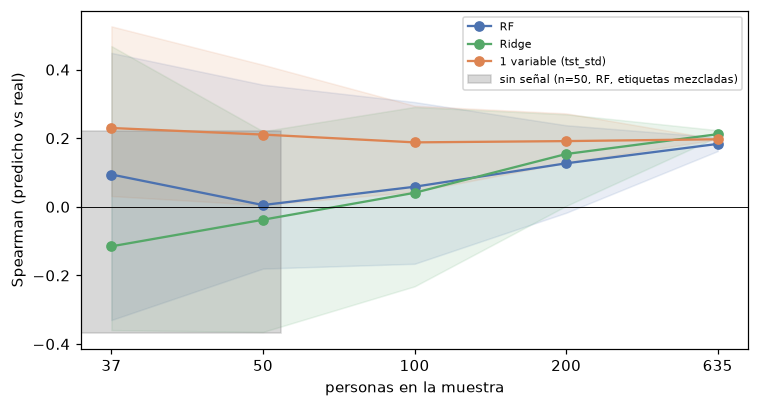

In [10]:
real = L[L.kind == "real"]; ns = sorted(real.n.unique())
fig, ax = plt.subplots(figsize=(7, 3.8))
cols = {"RF": "#4C72B0", "Ridge": "#55A868", f"1 variable ({A_PRIORI})": "#DD8452"}
for mod, c in cols.items():
    q = real[real.modelo == mod].groupby("n").rho.quantile([.05, .5, .95]).unstack()
    ax.fill_between(range(len(ns)), q[.05], q[.95], color=c, alpha=.12); ax.plot(range(len(ns)), q[.5], "o-", color=c, label=mod)
nul = L[(L.kind != "real") & (L.modelo == "RF")].rho
ax.axhspan(nul.quantile(.05), nul.quantile(.95), xmin=0, xmax=.3, color="grey", alpha=.3, label="sin señal (n=50, RF, etiquetas mezcladas)")
ax.axhline(0, color="k", lw=.6); ax.set_xticks(range(len(ns))); ax.set_xticklabels([str(n) for n in ns]); ax.set_xlabel("personas en la muestra"); ax.set_ylabel("Spearman (predicho vs real)")
ax.legend(fontsize=7.5); plt.tight_layout(); plt.show()

## 6. Otros cuestionarios y generalización entre años

Misma prueba con los demás cuestionarios (todas las personas, validación cruzada repetida 5×10) y la prueba nativa de GLOBEM: **entrenar con 3 años y probar en el 4.º** (se compara contra predecir el promedio).
Nota: GLOBEM dice tener 497 participantes únicos en 705 persona-años, pero los pid no se repiten entre años, así que **no se puede garantizar que una misma persona no aparezca en entrenamiento y prueba**
(en la validación por año, la misma persona podría estar en dos años). Es una limitación de los datos públicos.

In [11]:
rows = []
for o in OUTC:
    Mo = A[FEATS + [o, "year"]].dropna(subset=[o]).copy(); Mo[FEATS] = Mo[FEATS].fillna(Mo[FEATS].median())
    Xo, yo = Mo[FEATS].reset_index(drop=True), Mo[o].reset_index(drop=True)
    d = {"cuestionario": o, "n": len(yo)}
    for kind in ("RF", "Ridge"):
        rh, gn = [], []
        for r in range(10):
            oof, base = cv_oof(Xo, yo, SEED + r, kind); rh.append(spearmanr(yo, oof).correlation); gn.append(1 - np.abs(yo - oof).mean() / np.abs(yo - base).mean())
        d[f"{kind} Spearman"] = f"{np.mean(rh):.2f} ± {np.std(rh):.2f}"; d[f"{kind} MAE vs promedio"] = f"{np.mean(gn):+.1%}"
    d[f"{A_PRIORI} sola (Spearman)"] = f"{spearmanr(Xo[A_PRIORI], yo).correlation:+.2f}"
    d["nota"] = "tiene ítems de sueño" if o in ("CES-D 10", "BDI-II") else "sin ítems de sueño"
    rows.append(d)
print("Validación cruzada de 5 grupos, repetida 10 veces, todas las personas")
pd.DataFrame(rows).set_index("cuestionario")

Validación cruzada de 5 grupos, repetida 10 veces, todas las personas


,n,RF Spearman,RF MAE vs promedio,Ridge Spearman,Ridge MAE vs promedio,tst_std sola (Spearman),nota
cuestionario,,,,,,,
PSS-10,635,0.18 ± 0.01,+1.3%,0.21 ± 0.01,+2.2%,+0.20,sin ítems de sueño
STAI,127,0.20 ± 0.07,+1.3%,0.10 ± 0.08,-0.5%,+0.15,sin ítems de sueño
CES-D 10,438,0.21 ± 0.02,+3.4%,0.25 ± 0.01,+4.3%,+0.27,tiene ítems de sueño
BDI-II,633,0.27 ± 0.01,+3.8%,0.30 ± 0.01,+4.6%,+0.30,tiene ítems de sueño


In [12]:
rows = []
for y_out in range(1, 5):
    tr, te = M.year != y_out, M.year == y_out
    mdl = RandomForestRegressor(n_estimators=300, max_depth=5, random_state=SEED, n_jobs=-1).fit(M.loc[tr, FEATS], M.loc[tr, Y])
    p = mdl.predict(M.loc[te, FEATS]); yt = M.loc[te, Y]; b = M.loc[tr, Y].mean()
    rows.append({"año de prueba": y_out, "n prueba": int(te.sum()), "Spearman": round(spearmanr(yt, p).correlation, 2), "MAE modelo": round(np.abs(yt - p).mean(), 2),
                 "MAE promedio": round(np.abs(yt - b).mean(), 2), "mejora": f"{1 - np.abs(yt - p).mean() / np.abs(yt - b).mean():+.1%}"})
print(f"Etiqueta: {Y}. Entrenar con 3 años, probar en el 4.º")
pd.DataFrame(rows).set_index("año de prueba")

Etiqueta: PSS-10. Entrenar con 3 años, probar en el 4.º


,n prueba,Spearman,MAE modelo,MAE promedio,mejora
año de prueba,,,,,
1,128,0.33,5.01,5.23,+4.2%
2,197,0.23,5.18,5.27,+1.7%
3,129,0.16,5.31,5.26,-0.8%
4,181,0.20,5.59,5.85,+4.3%


## Lectura de los resultados (exploratorio; no es el desempeño de HapSleep)

**1. El supuesto de la tesis se confirma con 10 veces más datos.** Una noche no predice la siguiente (autocorrelación entre −0.04 y +0.07), pero el resumen por persona es muy estable:
las medias dan 0.93 a 0.98 de confiabilidad entre noches pares e impares, y la variación de la duración del sueño y la del horario de acostarse, 0.84. Comparando la primera mitad del periodo con la segunda,
las medias siguen en 0.82 a 0.93 y la regularidad baja (0.69 la duración, 0.55 el horario): la regularidad es estable, pero cambia algo con el tiempo. Esto respalda agregar por persona (media y variación), con n = 617 a 645 persona-años.

**2. Lo que sí se relaciona con los cuestionarios es la regularidad, no el sedentarismo.** Tras corregir por 28 pruebas, 10 relaciones resisten. Las más fuertes son la **variación de la duración del sueño**
(BDI-II +0.30, CES-D +0.27, PSS-10 +0.20) y la **variación del horario de acostarse** (BDI-II +0.26, CES-D +0.25, STAI +0.25, PSS-10 +0.18); dormir menos en promedio aporta poco (−0.13 a −0.16).
Eficiencia, minutos despierto, pasos y minutos sedentarios no pasan la corrección. El signo de la regularidad es el mismo en las 4 cohortes, incluida la del 2020; el de las horas dormidas cambia de tamaño entre años.
**Precaución:** BDI-II y CES-D incluyen ítems de sueño, así que parte de esa relación es mecánica; con PSS-10, que no los tiene, la relación es menor (+0.20 y +0.18). Es una asociación concurrente, no una predicción.

**3. La alerta del sedentarismo se confirma por otro camino.** En GLOBEM los minutos sedentarios y los activos suman exactamente 1440 todos los días, de modo que "sedentario" es "1440 menos activo" (incluye el tiempo dormido).
Entre personas, se correlaciona −0.92 con los pasos, así que no aporta información propia. Los días con casi cero movimiento (posible reloj sin usar) son pocos (1.1 %). En LifeSnaps, esa variable salía como factor principal;
aquí no se relaciona con ningún cuestionario. Refuerza la decisión de **no presentar "sedentarismo" como hallazgo** y de poner la regularidad como grupo principal a vigilar.

**4. Con ~50 personas, un Random Forest no se distingue del azar si la señal es débil.** Con PSS-10 como etiqueta sustituta, la señal completa es de Spearman ≈ 0.2. A n = 50, el Random Forest da una mediana de 0.01
(entre −0.18 y 0.36 en el 90 % de las corridas), prácticamente igual a lo que sale con las etiquetas mezcladas (−0.37 a 0.22), y es **peor que predecir el promedio en 3 de cada 4 corridas** (error medio). Solo en el 12 % de las corridas llega a 0.30.
Con todas las personas (n = 635) mejora al promedio en el 100 % de las corridas, pero por poco (+1.3 %). **Una sola variable elegida de antemano (la variación de la duración del sueño) rinde igual o mejor que el modelo con 11 variables** a todos los tamaños
(a n = 50: mediana 0.21 contra 0.01 del Random Forest), y la regresión lineal regularizada tampoco mejora al Random Forest con pocos datos. El Random Forest sigue siendo la opción por su interpretabilidad (decisión cerrada), pero con ~50 personas **no conviene que su aprobación dependa de un umbral de Spearman o de MAE**.

**5. La generalización entre años falla en 2020.** Entrenando con tres años y probando en el cuarto, el Spearman va de 0.16 a 0.33 y mejora al promedio en 3 de 4 años; en la primavera de 2020 (pandemia) queda 0.8 % peor que predecir el promedio.

**Qué implica para el paper y para los criterios de evaluación**
- GLOBEM **no puede ser la prueba de concepto principal de "riesgo de mala calidad de sueño"**: no tiene PSQI. Sí puede entrar como **evidencia de apoyo**: estabilidad por persona, variables de regularidad y alerta del sedentarismo, con una muestra universitaria 10 veces mayor.
- Los criterios de la Tabla 15 que más riesgo tienen con ~50 personas son Spearman ≥ 0,50 (llegó a 0.30 en solo 12 % de las corridas con una señal débil) y "MAE menor que el promedio" (el Random Forest lo cumple en 25 % de las corridas a n = 50). Con el PSQI la señal puede ser mayor, porque mide sueño y no estrés, pero esto no se sabe hasta tenerlo.
  Un criterio más seguro es reportar los intervalos y comparar contra el azar (ROC-AUC con su intervalo), y presentar una variable simple de regularidad como línea base.
- **Falta lo esencial:** el PSQI de los estudiantes de Lima, y datos de pulso, HRV, SpO2 y respiración, que GLOBEM no tiene.

**Límites.** La etiqueta (estrés, ansiedad, depresión) no es calidad de sueño; las variables son solo sueño y pasos; los pid no se repiten entre años, por lo que una misma persona podría estar en dos años (497 únicos en 705 persona-años según PhysioNet);
una noche válida es la que tiene al menos 180 minutos dormidos, criterio nuestro; la ganancia del Random Forest en etiquetas mezcladas no es cero por un efecto conocido de la validación cruzada con señal nula; el resumen por persona usa todo el periodo, mientras que HapSleep usará una ventana de 14 días.